# Phase 1 EDA: SentiTurca `movies`

Raw data, before cleaning. Text is read from train and validation only. For test we only look at numbers (class counts, lengths), never at the reviews themselves.

In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

import config

dataset = load_dataset(config.DATASET_NAME, config.DATASET_CONFIG)
train_df = dataset["train"].to_pandas()
validation_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()
print(dataset["train"].features)

{'text': Value('string'), 'label': ClassLabel(names=['negative', 'positive'])}


## 1. Class balance
More than 70% of the reviews are positive in every split. A model that always says "positive" already gets ~71% accuracy, so accuracy alone is a weak metric. This is why macro-F1 is our main metric.

        split  negative  positive  positive_share
0       train     16573     43838           0.726
1  validation      2594      6311           0.709
2        test      2594      6340           0.710


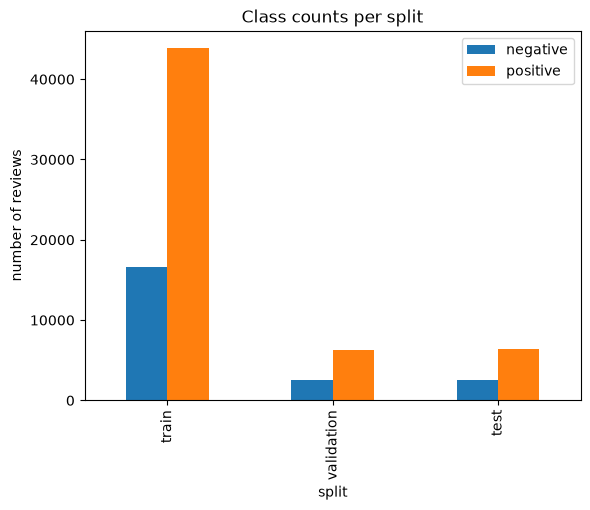

In [2]:
rows = []
for split_name, df in [("train", train_df), ("validation", validation_df), ("test", test_df)]:
    negative = (df["label"] == 0).sum()
    positive = (df["label"] == 1).sum()
    rows.append({"split": split_name, "negative": negative, "positive": positive,
                 "positive_share": round(positive / len(df), 3)})
balance_df = pd.DataFrame(rows)
print(balance_df)

balance_df.set_index("split")[["negative", "positive"]].plot(kind="bar")
plt.title("Class counts per split")
plt.ylabel("number of reviews")
plt.show()

## 2. Text length (in words)
The dataset card suggests that train texts are much longer than validation/test texts (based on the byte sizes). Let us check.

         train  validation    test
count  60411.0      8905.0  8934.0
mean      46.9        46.2    46.4
std       78.3        72.7    82.1
min        0.0         1.0     1.0
25%       15.0        15.0    15.0
50%       27.0        27.0    27.0
75%       51.0        51.0    51.0
max     4222.0      1262.0  3536.0


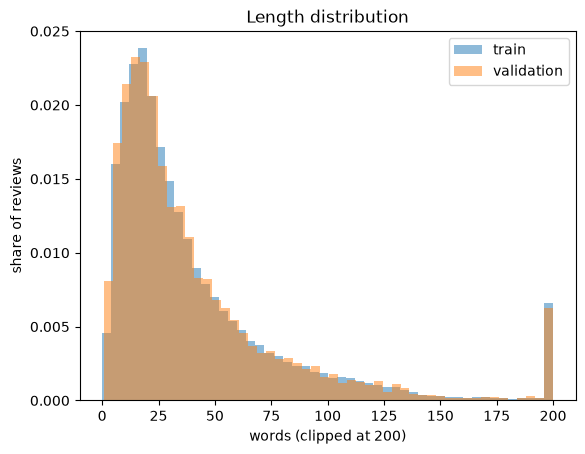

In [3]:
train_words = train_df["text"].str.split().str.len()
validation_words = validation_df["text"].str.split().str.len()
test_words = test_df["text"].str.split().str.len()

summary_df = pd.DataFrame({"train": train_words.describe(), "validation": validation_words.describe(),
                           "test": test_words.describe()})
print(summary_df.round(1))

# Clip at 200 words only for the plot, a few reviews have thousands of words.
plt.hist(train_words.clip(upper=200), bins=50, alpha=0.5, density=True, label="train")
plt.hist(validation_words.clip(upper=200), bins=50, alpha=0.5, density=True, label="validation")
plt.xlabel("words (clipped at 200)")
plt.ylabel("share of reviews")
plt.legend()
plt.title("Length distribution")
plt.show()

Finding: the length distributions match (mean about 46 words, median 27). The byte sizes in the dataset card are wrong for train, not a real difference.

## 3. Empty and very short texts

In [4]:
for split_name, words in [("train", train_words), ("validation", validation_words), ("test", test_words)]:
    print(split_name, "| 0 words:", (words == 0).sum(), "| <=2 words:", (words <= 2).sum(),
          "| <=5 words:", (words <= 5).sum(), "| >500 words:", (words > 500).sum())

very_short_df = train_df[train_words <= 1].sample(12, random_state=config.SEED)
print()
print(very_short_df[["label", "text"]].to_string())

train | 0 words: 2 | <=2 words: 571 | <=5 words: 2794 | >500 words: 454
validation | 0 words: 0 | <=2 words: 94 | <=5 words: 415 | >500 words: 59
test | 0 words: 0 | <=2 words: 82 | <=5 words: 424 | >500 words: 66

       label                                                                                                                 text
32738      1                                                                                                            bayılırım
4171       0                                                                                                               sıkıcı
53355      0                                                                                                             fiyasko.
35915      0                                                                                                            fantastik
1540       1                                                                                         https://youtu.be/NiZvC621J5I
44168

## 4. URLs and spoiler tags
We keep them: BERT and LLMs read raw text, and removing them could remove signal.

In [5]:
for split_name, df in [("train", train_df), ("validation", validation_df)]:
    has_url = df["text"].str.contains("http", case=False).sum()
    has_spoiler = df["text"].str.contains("[spoiler]", case=False, regex=False).sum()
    print(split_name, "| contains http:", has_url, "| contains [spoiler]:", has_spoiler)

train | contains http: 392 | contains [spoiler]: 385
validation | contains http: 70 | contains [spoiler]: 65


## 5. Label noise (weak labels)
Labels come from star ratings, not from a human reading the text. A quick keyword check shows how often text and label disagree. This is a rough check, not a measurement.

In [6]:
praise_in_negative = train_df[(train_df["label"] == 0) & train_df["text"].str.contains("tavsiye ederim", case=False)]
criticism_in_positive = train_df[(train_df["label"] == 1) & train_df["text"].str.contains("berbat", case=False)]
print("negative label but contains 'tavsiye ederim':", len(praise_in_negative))
print("positive label but contains 'berbat':", len(criticism_in_positive))
print()
for text in praise_in_negative["text"].head(4):
    print("-", text[:200].replace("\n", " "))

negative label but contains 'tavsiye ederim': 111
positive label but contains 'berbat': 171

- ya muhtesem bir film..cd.de izledim ve resmen bayıldım..cocuk filmi diye bir sey bekliyordum ve acıkcası her yastan insanın izleyebileceği inanılmaz komik ve orjinal bir film olmus..sunny,violet ve kl
- Vakit kaybı kesinlikle. Uzak durmanızı tavsiye ederim.
- İster istemez Nefes filmi ile kıyasladığımız Dağ maalesef Nefes filminin düzeyine çıkamıyor. Kötümüydü ? Kesinlikle hayır. Ama filmi izlediğinizde adını koyamadığınız bir takım eksikler göreceksiniz. 
- İskoçyada bir adamı ailesi terkederse ne olur konulu, uç bir filme hoş geldiniz, filmden çıkarken memnun, mutlu ve güzel duygularla ayrılmayacağınızı garanti eder, j. mcavoy ile bol sıkıntılı dakikaka


## 6. Duplicates (counts only)
Text is lowercased and spaces are collapsed before comparing.

In [7]:
def make_key(df):
    lowered = df["text"].str.lower()
    collapsed = lowered.str.replace(r"\s+", " ", regex=True)
    return collapsed.str.strip()

train_keys = make_key(train_df)
validation_keys = make_key(validation_df)
test_keys = make_key(test_df)

print("extra copies inside train:", train_keys.duplicated().sum())
print("extra copies inside validation:", validation_keys.duplicated().sum())
print("extra copies inside test:", test_keys.duplicated().sum())
print("validation rows also in train:", validation_keys.isin(set(train_keys)).sum())
print("test rows also in train:", test_keys.isin(set(train_keys)).sum())
print("test rows also in validation:", test_keys.isin(set(validation_keys)).sum())

extra copies inside train: 77
extra copies inside validation: 2
extra copies inside test: 1


validation rows also in train: 24


test rows also in train: 17
test rows also in validation: 5


## Summary and decisions
- Labels: 0 = negative, 1 = positive (checked by reading train examples).
- Classes are imbalanced (about 71% positive), so macro-F1 and the majority baseline matter.
- 2 empty train texts, a few hundred very short ones (kept: they are real reviews).
- Small overlaps between splits (0.2-0.4%). Decision D-014: remove them from train, keep validation and test official.
- No URL/spoiler/punctuation cleaning.